In [2]:
import anndata as ad
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import pandas as pd
rng = np.random.default_rng()

(400, 50)


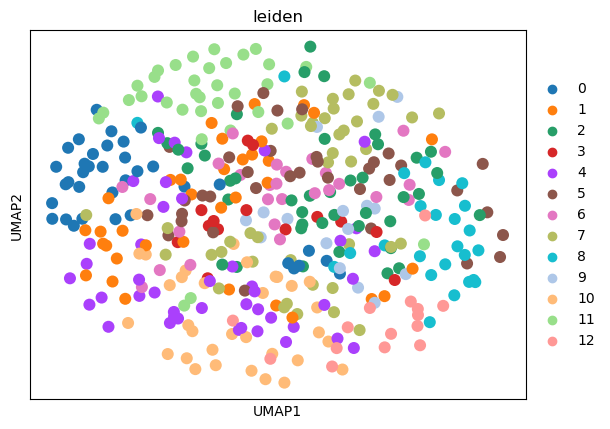

Index([], dtype='object')
Empty DataFrame
Columns: []
Index: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, ...]

[400 rows x 0 columns]


In [3]:
X = rng.uniform(0,100, size=((400,4000)))
adata = ad.AnnData(X=X)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes= 400)
adata_hvg = adata[:,adata.var["highly_variable"]].copy()
sc.tl.pca(adata_hvg, svd_solver = "arpack")
print(adata_hvg.obsm["X_pca"].shape)

sc.pp.neighbors(adata_hvg, n_neighbors = 15, n_pcs = 30)
sc.tl.umap(adata_hvg)
sc.tl.leiden(adata_hvg, flavor="igraph", n_iterations = 2)
sc.pl.umap(adata_hvg, color="leiden")
print(adata.obs.columns)
print(adata.obs)


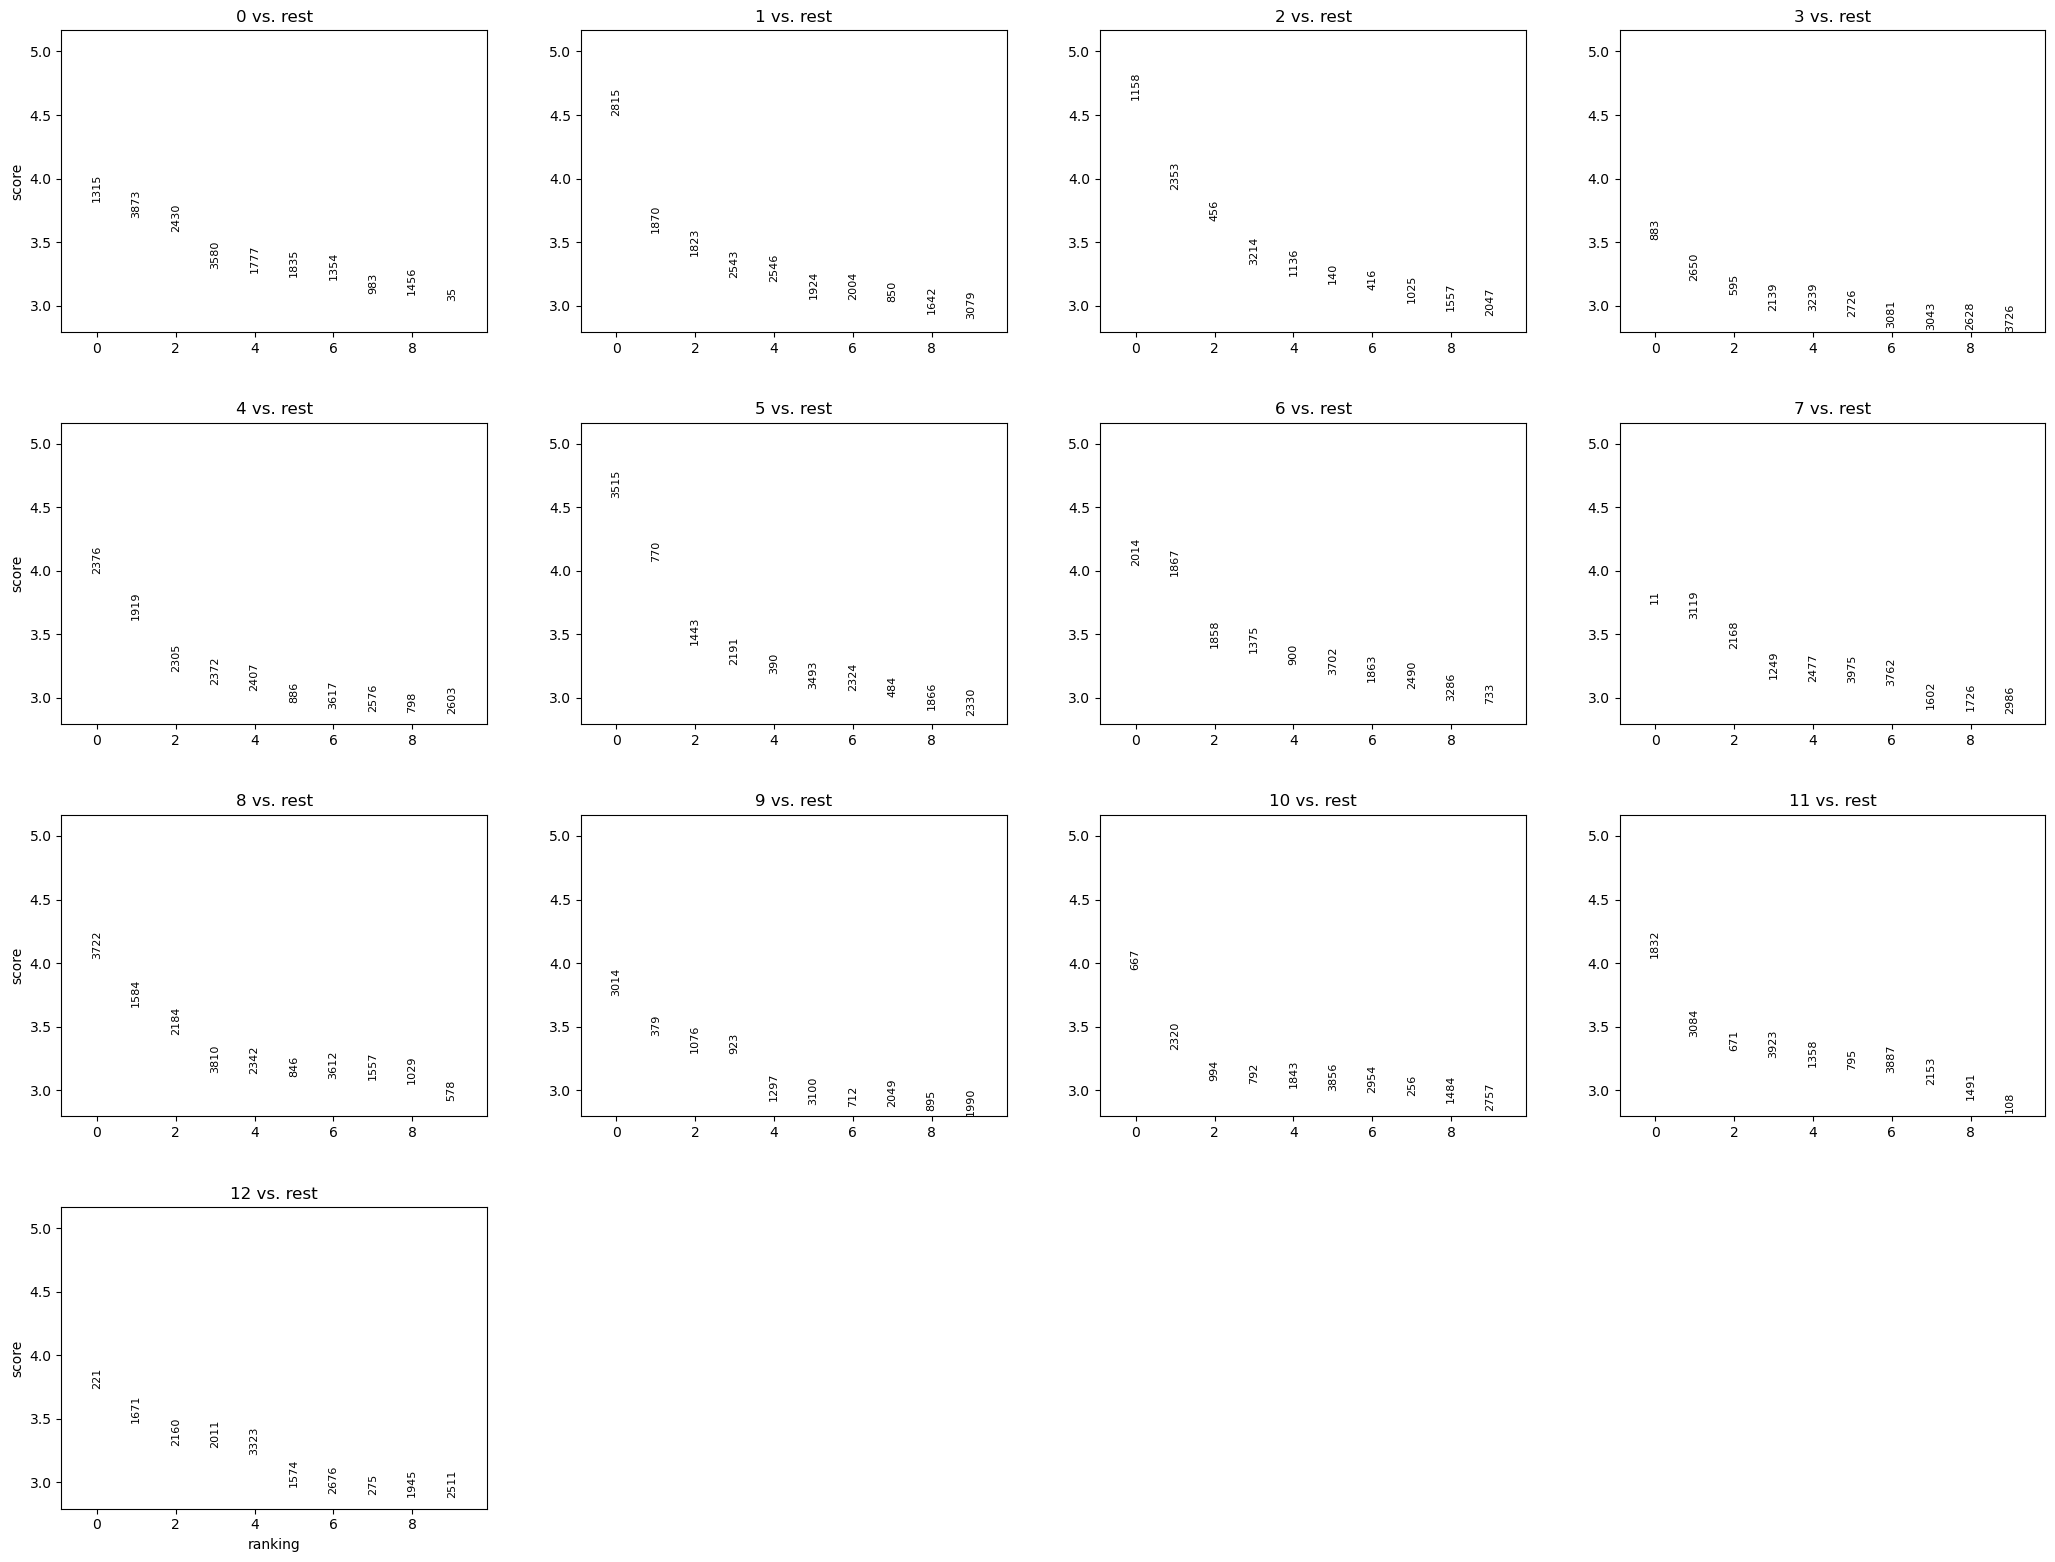

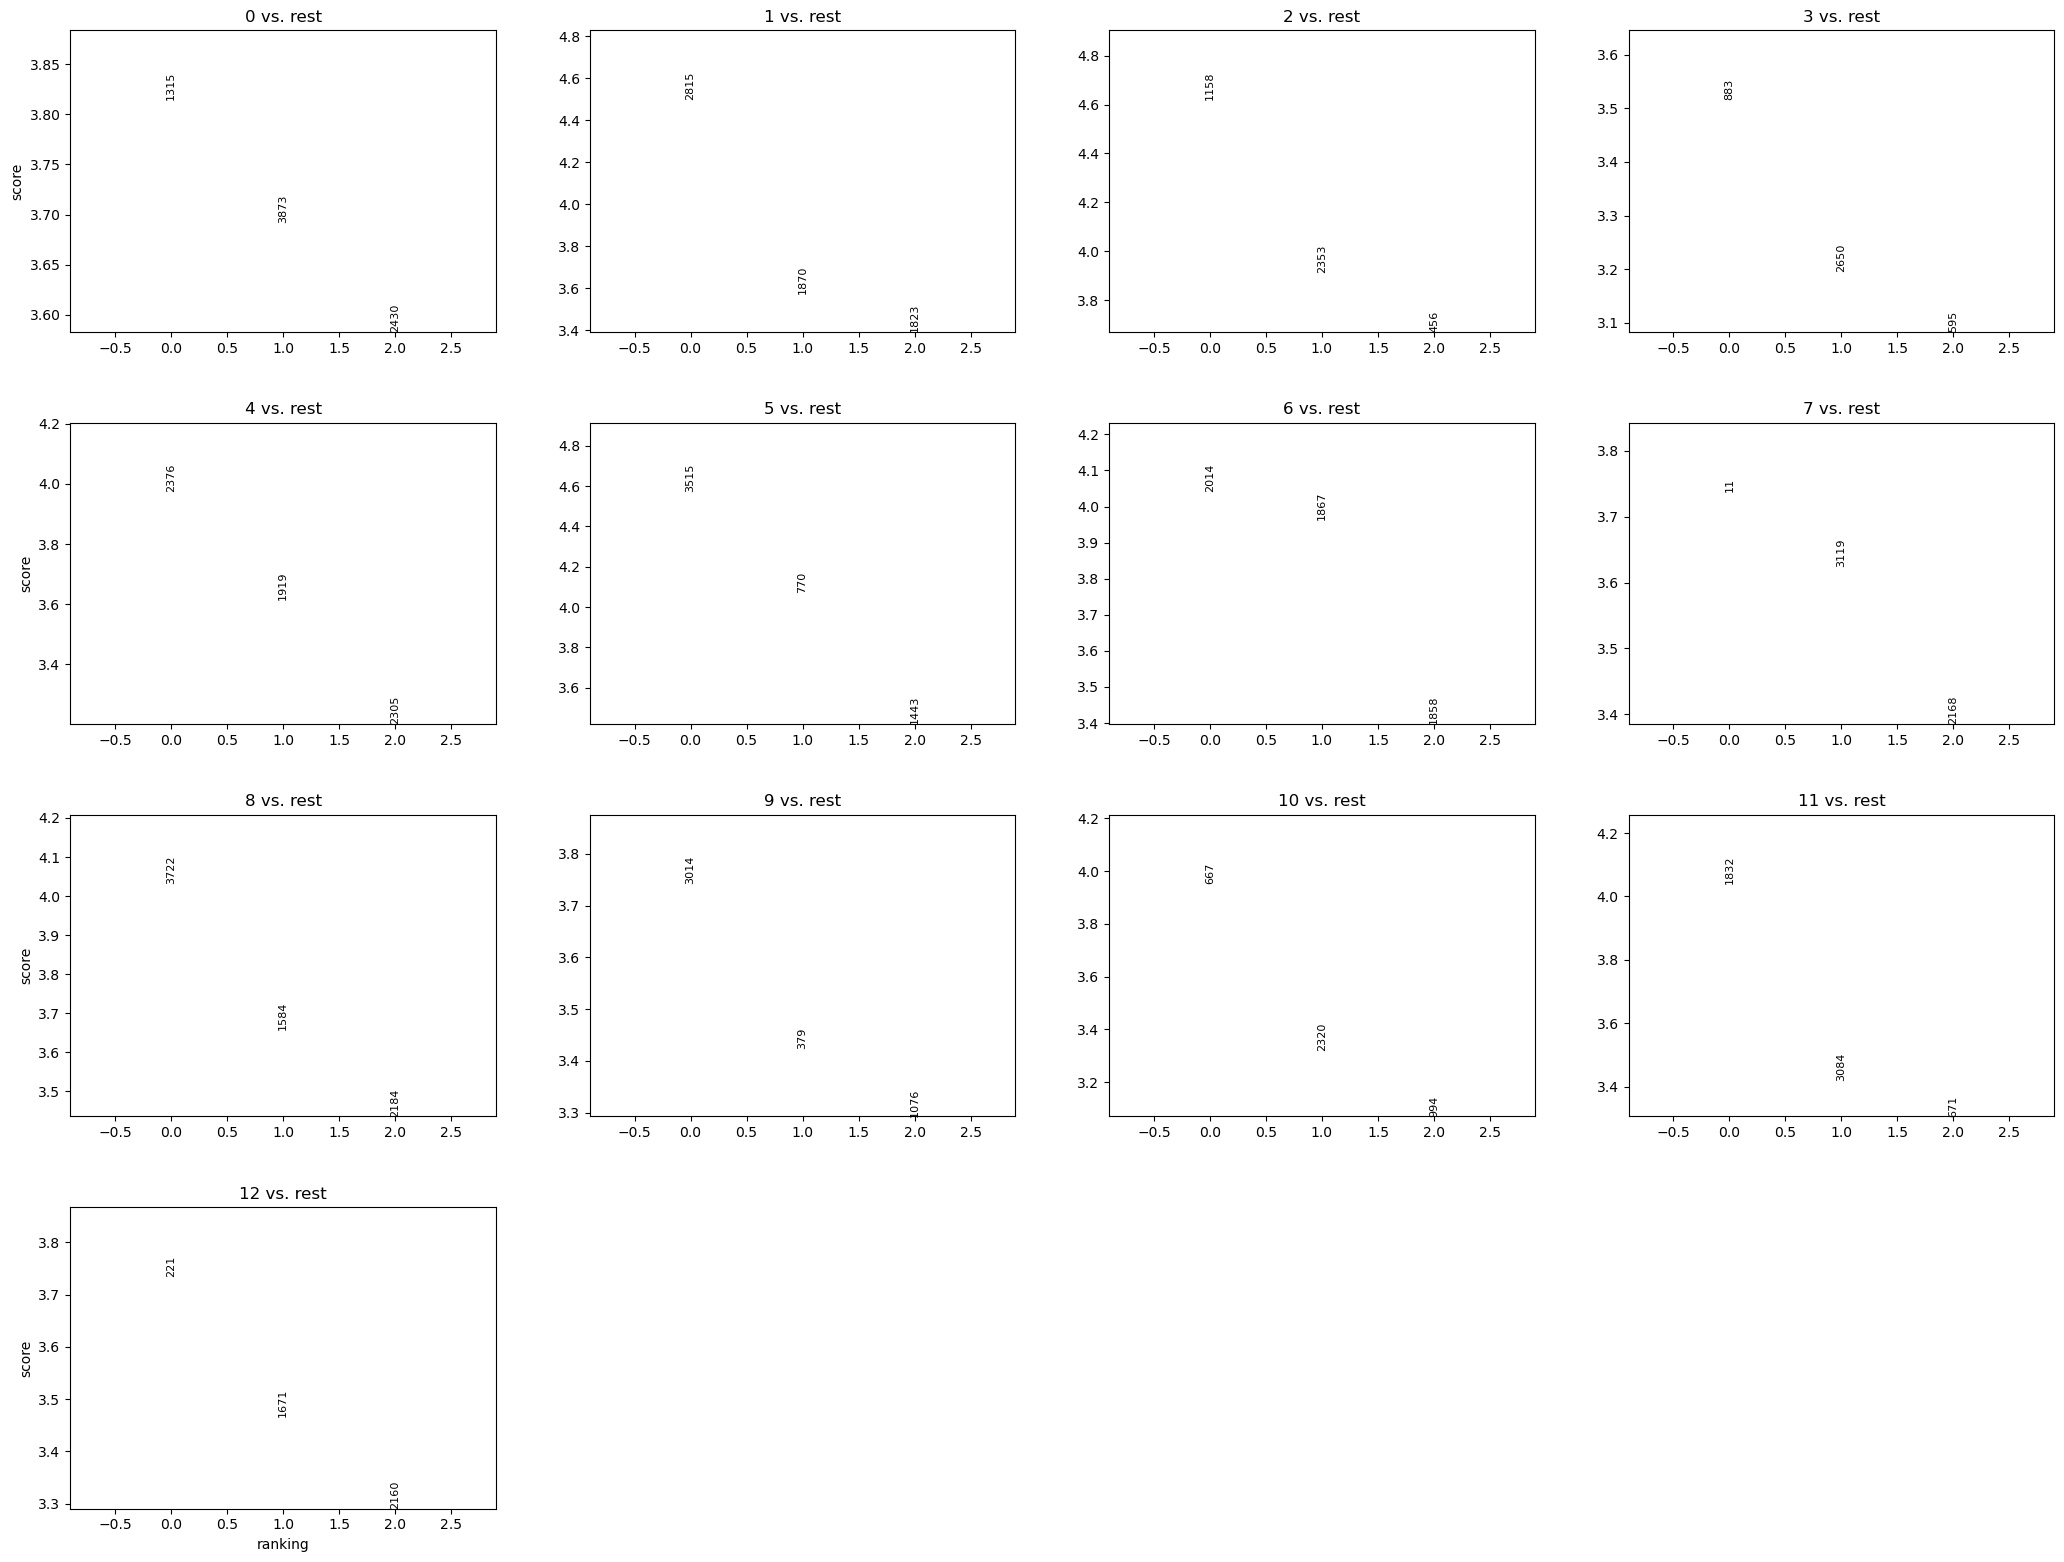

In [4]:
sc.tl.rank_genes_groups(adata_hvg, groupby = "leiden", method = "wilcoxon")
sc.pl.rank_genes_groups(adata_hvg, n_genes = 10)
sc.pl.rank_genes_groups(adata_hvg, n_genes = 3, sharey=False)

In [11]:
markers = sc.get.rank_genes_groups_df(adata_hvg, group = '0')
top_markers = markers[markers['pvals_adj'] < 0.25]
top_markers_logs = top_markers.sort_values( by="logfoldchanges", ascending = False)

print(markers)
print(top_markers.head(10))



     names    scores  logfoldchanges     pvals  pvals_adj
0     1315  3.814221        0.637471  0.000137   0.222659
1     3873  3.691815        0.645157  0.000223   0.222659
2     2430  3.583010        0.532929  0.000340   0.271726
3     3580  3.288330        0.581700  0.001008   0.458000
4     1777  3.261129        0.512929  0.001110   0.458000
...    ...       ...             ...       ...        ...
3995   770 -3.150812       -0.649948  0.001628   0.458000
3996  2732 -3.235439       -0.598864  0.001215   0.458000
3997  1183 -3.236950       -0.673493  0.001208   0.458000
3998  3397 -3.706927       -0.801462  0.000210   0.222659
3999  2009 -4.179927       -0.891168  0.000029   0.116641

[4000 rows x 5 columns]
     names    scores  logfoldchanges     pvals  pvals_adj
0     1315  3.814221        0.637471  0.000137   0.222659
1     3873  3.691815        0.645157  0.000223   0.222659
3998  3397 -3.706927       -0.801462  0.000210   0.222659
3999  2009 -4.179927       -0.891168  0.000029 